# 08 · Feature selection, done right (+ XGBoost, and trees beyond yes/no)

Three things today, one main one:
1. **XGBoost**: what's different from last week's boosters, what its hyperparameters do, and whether it changes the results.
2. **Feature selection**: why it matters, the kinds of selection, a worked example, the leakage trap, and how to put it in *any* pipeline and in ours.
3. **Beyond binary**: the same decision tree on a 3-class target and on a number.

This notebook is short on purpose: the rest of the class is yours, in your pipeline. Before running a cell marked 🤔, **guess first**. Cells marked ✏️ invite you to change a value and run again.

<div style="background-color:#fff8e1; border-left:6px solid #f9a825; padding:10px 14px; border-radius:4px">📝 <b>Reminder: the course feedback form</b> is still open (anonymous, about 3 minutes). Fill it in as you work today: <a href="https://forms.gle/ztjiyG9f5F6iDCqH8">https://forms.gle/ztjiyG9f5F6iDCqH8</a></div>

## 1 · Setup

`course_helpers.py` (next to this notebook) is **last week's pipeline in one file**: the same functions and the same `config.yaml`, so this notebook runs on its own and only this week's *new* code appears here. Open it if you want to look anything up. The data is in `data/`.

In [1]:
#%pip install xgboost

In [2]:
import time
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, SelectorMixin, f_classif, mutual_info_classif
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

import course_helpers
from course_helpers import *        # last week's pipeline: build_pipeline, cross_validate_pipeline, CONFIG, ...
from sklearn.model_selection import cross_val_predict

plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e4e0"})
BLUE, ORANGE = "#2a78d6", "#eb6834"

X_dev, y_dev, extras_dev, cv = load_course_data()
print(f"development set: {X_dev.shape[0]} rows, {X_dev.shape[1]} columns · base rate {y_dev.mean():.3f}")

development set: 5771 rows, 10 columns · base rate 0.451


## 2 · XGBoost: what's different from last week's boosters

![XGBoost](images/xgboost_idea.png)

The **algorithm is last week's**: trees added one at a time, each fitting what the previous ones still get wrong. What changes is **how each tree is built** (more brakes, inside the split itself) and **how it's engineered** (speed, missing values):

| | `GradientBoostingClassifier` | `HistGradientBoostingClassifier` | `XGBClassifier` |
|---|---|---|---|
| How a split is chosen | an ordinary regression tree fit to the residuals | gain from gradients **and** second derivatives, with an L2 penalty | the same, plus a **minimum gain** to split and a **minimum weight** per leaf |
| Brakes against overfitting | learning rate, tree size, `subsample`, `max_features` | learning rate, tree size, `l2_regularization`, `max_features` | learning rate, tree size, `subsample`, `colsample_*`, **`reg_lambda`, `reg_alpha`, `gamma`, `min_child_weight`** |
| Speed | exact splits, one CPU core: slow on large data | binned features, all cores | binned features, all cores (and GPU) |
| Missing values | refuses `NaN` | learns where gaps go | learns where gaps go |

### 2.1 The hyperparameters, and what each one does
🆕 = only XGBoost has it.

| Hyperparameter (XGBoost default) | What it does | Raise it to... | `GradientBoosting` | `HistGradientBoosting` |
|---|---|---|---|---|
| `n_estimators` (100), `learning_rate` (0.3) | number of trees; how much each tree counts | more trees + lower rate: slower, smoother | same (`n_estimators`, default rate **0.1**) | `max_iter`, `learning_rate` |
| `max_depth` (6) | how deep each tree grows | fit more complex patterns (and noise) | `max_depth` (default **3**) | `max_depth` / `max_leaf_nodes` |
| `min_child_weight` (1) 🆕 | a leaf needs this much "weight": rows the model is still unsure about count most (a row with p = 0.5 counts 0.25; one it already predicts confidently counts almost 0) | stop splitting on a few rows, especially ones already predicted well | like `min_samples_leaf`, but counts rows | `min_samples_leaf` (counts rows) |
| `gamma` (0) 🆕 | a split is only made if it improves the loss by at least `gamma` | **prune** splits that barely help: fewer, smaller trees | (`min_impurity_decrease`, rarely used) | — |
| `reg_lambda` (1) | L2 penalty: shrinks every leaf's value towards 0 | smaller corrections per tree, especially from small leaves | — | `l2_regularization` |
| `reg_alpha` (0) 🆕 | L1 penalty: sets weak leaves' values to exactly 0 | drop leaves (and splits) that barely help | — | — |
| `subsample` (1) | share of rows each tree sees | more randomness between trees | `subsample` | — |
| `colsample_bytree` / `_bylevel` / `_bynode` (1) | share of columns per tree / per depth level / per split | more randomness, less reliance on one strong feature | `max_features` (per split) | `max_features` (per split) |
| `scale_pos_weight` (1) | weight of the positive class | more recall, less precision | `sample_weight` | `class_weight` |

Two things stand out:
- XGBoost's **defaults are aggressive**: depth 6 and learning rate 0.3, against `GradientBoostingClassifier`'s depth 3 and 0.1. Untuned, it overfits more easily.
- Its **new brakes** (`gamma`, `min_child_weight`, `reg_alpha`, `reg_lambda`) act while each tree is built, by refusing or shrinking splits. The older brakes (learning rate, subsampling) only act between trees.

### 2.2 One knob at a time: the new brakes
We start from trees built to overfit (depth 8, learning rate 0.3, every brake off), then turn up **one** brake at a time. Fold 1 of COMPAS: train ROC-AUC, validation ROC-AUC, and the total number of leaves in the 100 trees.

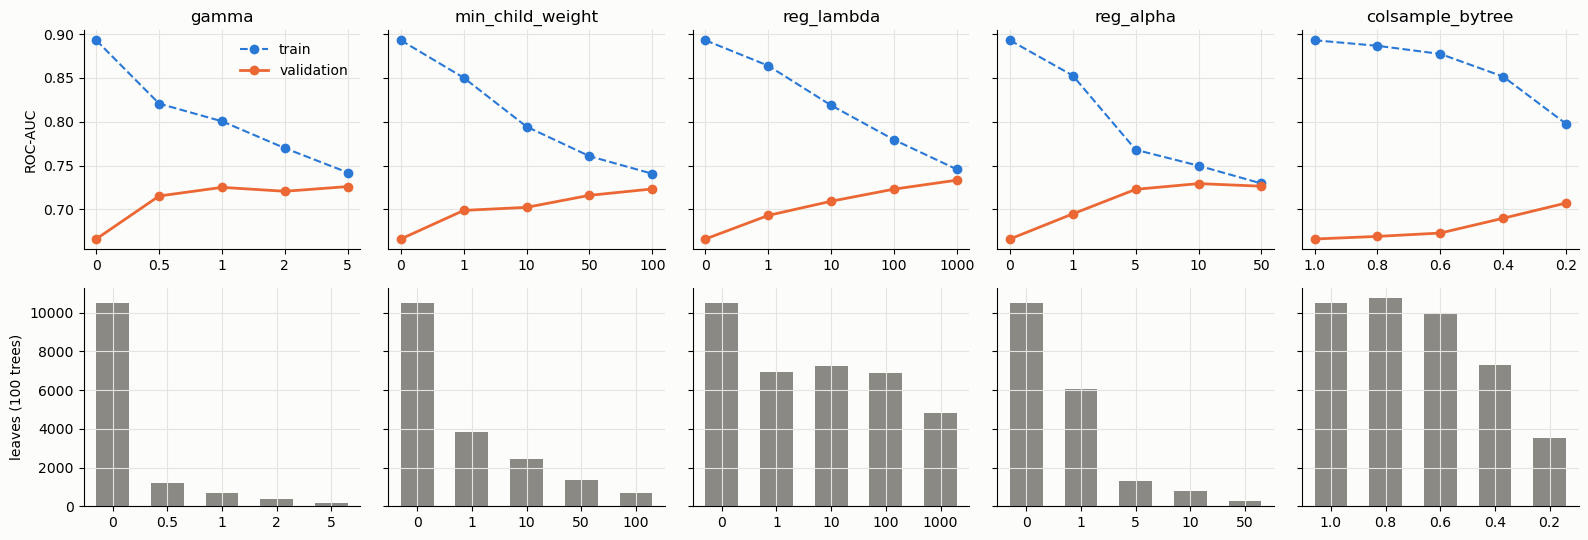

In [3]:
train_idx, val_idx = next(cv.split(X_dev, y_dev))
prep = build_preprocessor(CONFIG["preprocessing"]).fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
X_tr, y_tr = prep.transform(X_dev.iloc[train_idx]), y_dev.iloc[train_idx]
X_va, y_va = prep.transform(X_dev.iloc[val_idx]), y_dev.iloc[val_idx]

no_brakes = {"n_estimators": 100, "max_depth": 8, "learning_rate": 0.3,      # ✏️ try max_depth 3
             "reg_lambda": 0, "min_child_weight": 0, "gamma": 0, "random_state": 42, "n_jobs": -1}
knobs = {"gamma": [0, 0.5, 1, 2, 5],
         "min_child_weight": [0, 1, 10, 50, 100],
         "reg_lambda": [0, 1, 10, 100, 1000],
         "reg_alpha": [0, 1, 5, 10, 50],
         "colsample_bytree": [1.0, 0.8, 0.6, 0.4, 0.2]}
rows = []
for knob, values in knobs.items():
    for value in values:
        booster = XGBClassifier(**{**no_brakes, knob: value}).fit(X_tr, y_tr)
        rows.append({"knob": knob, "value": str(value),
                     "train": roc_auc_score(y_tr, booster.predict_proba(X_tr)[:, 1]),
                     "validation": roc_auc_score(y_va, booster.predict_proba(X_va)[:, 1]),
                     "leaves": (booster.get_booster().trees_to_dataframe()["Feature"] == "Leaf").sum()})
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(2, len(knobs), figsize=(16, 5.5), sharey="row")
for col, knob in enumerate(knobs):
    part = sweep[sweep["knob"] == knob]
    x = range(len(part))
    axes[0, col].plot(x, part["train"], "o--", color=BLUE, lw=1.5, label="train")
    axes[0, col].plot(x, part["validation"], "o-", color=ORANGE, lw=2, label="validation")
    axes[1, col].bar(x, part["leaves"], color="#8a8984", width=0.6)
    axes[0, col].set_title(knob)
    for ax in axes[:, col]:
        ax.set_xticks(list(x)); ax.set_xticklabels(part["value"])
axes[0, 0].set_ylabel("ROC-AUC"); axes[1, 0].set_ylabel("leaves (100 trees)")
axes[0, 0].legend(frameon=False); plt.tight_layout(); plt.show()

Reading the plots (left to right = more brake):
- **`gamma`** acts fastest: requiring a minimum gain removes almost all leaves (about 10,000 → a few hundred), and the validation score **rises**: the removed splits were fitting noise.
- **`reg_alpha`** works the same way: L1 sets weak leaves to 0, so those splits disappear.
- **`reg_lambda`** removes far fewer leaves: it mostly **shrinks** what each leaf predicts, so small leaves count less. It ends with the best validation score here.
- **`min_child_weight`** removes splits gradually, stopping leaves built on a few rows the model is unsure about.
- **`colsample_bytree`** gives each tree a random subset of the columns: fewer leaves and a better validation score only when it's strong (0.2–0.4 of 10 columns).

In every panel the **train–validation gap closes**: the brakes trade training fit for generalisation. Too much brake underfits, so these should be tuned.

<div style="background-color:#fdecea; border-left:6px solid #c62828; padding:10px 14px; border-radius:4px">⚠️ <b>Early stopping</b> (<code>early_stopping_rounds=30</code> with an <code>eval_set</code>) is another XGBoost brake: it stops adding trees when the eval-set loss stops improving. It looks at the eval set's labels, so the same rule as feature selection applies: the eval set must come from the <b>training</b> rows, never the CV validation fold or the test set. Our pipeline tunes <code>n_estimators</code> with nested CV instead, which is already leak-free.</div>

### 2.3 Speed and missing values
One fit of 100 trees on 10,000 rows × 30 columns, then a fit on COMPAS's raw numeric columns, **with** their gaps:

In [4]:
from sklearn.datasets import make_classification
X_big, y_big = make_classification(n_samples=10_000, n_features=30, n_informative=10, random_state=0)
boosters = {"GradientBoosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=0),
            "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, max_depth=3, early_stopping=False, random_state=0),
            "XGBoost": XGBClassifier(n_estimators=100, max_depth=3, n_jobs=-1, random_state=0)}
raw_numeric = X_dev[CONFIG["preprocessing"]["numeric_features"]]        # not imputed: has NaNs
rows = []
for name, model in boosters.items():
    start = time.time()
    model.fit(X_big, y_big)
    seconds = time.time() - start
    try:
        clone(model).fit(raw_numeric, y_dev)
        nan_ok = "yes"
    except ValueError:
        nan_ok = "no: ValueError"
    rows.append({"model": name, "fit time (s), 10k rows": round(seconds, 2), "fits with NaN?": nan_ok})
print(f"{int(raw_numeric.isna().sum().sum())} missing values in COMPAS's numeric columns")
pd.DataFrame(rows)

  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


691 missing values in COMPAS's numeric columns


,model,"fit time (s), 10k rows",fits with NaN?
0,GradientBoosting,8.65,no: ValueError
1,HistGradientBoosting,0.15,yes
2,XGBoost,0.09,yes


`GradientBoostingClassifier` is the slow one and refuses gaps. **`HistGradientBoostingClassifier` and XGBoost are both fast and both handle missing values**.

<div style="background-color:#e8f5e9; border-left:6px solid #2e7d32; padding:10px 14px; border-radius:4px"><b>🆕 New in the pipeline: <code>"xgboost"</code> in <code>_MODELS</code></b> &nbsp;·&nbsp; <code>src/model.py</code><br><code>from xgboost import XGBClassifier</code>, then add <code>"xgboost": XGBClassifier,</code> to <code>_MODELS</code>.</div>

In [5]:
#Adding XGBoost to our Pipeline
course_helpers._MODELS["xgboost"] = XGBClassifier

Its search space for tuning, in `config.yaml` (now with the two new brakes, `reg_alpha` and `gamma`):
```yaml
    xgboost:
      model__n_estimators: {type: int, low: 50, high: 600, log: true}
      model__learning_rate: {type: float, low: 0.01, high: 0.3, log: true}
      model__max_depth: {type: int, low: 1, high: 8}
      model__min_child_weight: {type: float, low: 1.0, high: 50.0, log: true}
      model__subsample: {type: float, low: 0.5, high: 1.0}
      model__colsample_bytree: {type: float, low: 0.5, high: 1.0}
      model__reg_lambda: {type: float, low: 0.01, high: 10.0, log: true}
      model__reg_alpha: {type: float, low: 0.001, high: 10.0, log: true}
      model__gamma: {type: float, low: 0.0, high: 5.0}
```

## 3 · Why select features?

A model only learns from the columns it gets. Columns with **no information** still cost something. To see it, we add `k` columns of pure random numbers to COMPAS and cross-validate three models on the same folds.

<div style="background-color:#fff8e1; border-left:6px solid #f9a825; padding:10px 14px; border-radius:4px">🤔 <b>Guess first:</b> with 100 useless columns added, which model suffers most: logistic regression, a decision tree, or XGBoost? And what happens to the training time?</div>

In [6]:
def add_noise_columns(X, k, seed=0):
    """Adds k columns of random numbers (no information about the target)."""
    rng = np.random.default_rng(seed)
    noise = pd.DataFrame(rng.normal(size=(len(X), k)), index=X.index, columns=[f"noise_{i:03d}" for i in range(k)])
    return pd.concat([X, noise], axis=1)

def config_with_noise(k):
    """The preprocessing config, with the k noise columns listed as numeric features."""
    return {**CONFIG["preprocessing"],
            "numeric_features": CONFIG["preprocessing"]["numeric_features"] + [f"noise_{i:03d}" for i in range(k)]}

models = {"logistic_regression": {"max_iter": 2000},
          "decision_tree": {"max_depth": 6, "random_state": 42},
          "xgboost":  {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 4, "random_state": 42, "n_jobs": -1}}
rows = []
for k in [0, 20, 100]:                                   # ✏️ try other numbers of noise columns
    X_noisy = add_noise_columns(X_dev, k)
    for name, params in models.items():
        start = time.time()
        scores = cross_val_score(build_pipeline(config_with_noise(k), {"type": name, "params": params}),
                                 X_noisy, y_dev, cv=cv, scoring="roc_auc")
        rows.append({"noise columns": k, "model": name, "ROC-AUC": scores.mean(), "seconds": time.time() - start})
table = pd.DataFrame(rows).pivot(index="model", columns="noise columns", values=["ROC-AUC", "seconds"])
table.round(3)

ROC-AUC               seconds              
noise columns           0      20     100     0      20     100
model                                                          
decision_tree         0.713  0.682  0.657   0.188  0.487  1.714
logistic_regression   0.718  0.714  0.702   0.204  0.314  0.772
xgboost               0.724  0.711  0.703   0.648  1.470  4.466

Every model gets **worse and slower**: the flexible ones (the tree, XGBoost) the most, because with enough random columns some split on noise always looks good on the training rows. Logistic regression suffers least: each useless column only adds one small coefficient.

So selection buys three things: **better scores** when there is noise, **faster** models, and models that are **easier to explain** (fewer features to account for). On real data you don't know which columns are noise: that's what selection is for.

## 4 · The kinds of feature selection

| Kind | How it decides | In scikit-learn | Good | Watch out |
|---|---|---|---|---|
| **Filter** | scores each feature **alone** against the target, keeps the best `k` | `SelectKBest(f_classif / mutual_info_classif, k=...)` | very fast, model-free | misses features that only matter together; you choose `k` |
| **Wrapper** | fits a model on subsets, drops the weakest, refits... | `RFE`, `SequentialFeatureSelector` | tailored to the model | slow (many fits); you choose how many to keep |
| **Embedded** | the model selects while it trains: L1 sets coefficients to 0, trees rank importances | `SelectFromModel(...)` | one fit, uses interactions (trees) | inherits the model's biases |
| **Combined** | several models **vote**; keep features with enough votes | our `VoteSelector` (below) | robust: one model's quirk isn't enough | slower: several fits |

All of them are **learned from the labels**. Keep that in mind for section 5.

Our pipeline uses the **combined** one, the worked example from last week: a random forest and gradient boosting vote for features with above-average importance, and an L1 logistic regression votes for features it doesn't shrink to zero. Since it's fitted, it's a class with scikit-learn's `fit` / `transform` contract (`SelectorMixin` provides `transform` and `get_feature_names_out` from `_get_support_mask`).

<div style="background-color:#e8f5e9; border-left:6px solid #2e7d32; padding:10px 14px; border-radius:4px"><b>🆕 New in the pipeline: <code>VoteSelector</code></b> &nbsp;·&nbsp; <code>src/model.py</code><br>Same as last week's worked example, with one change: the L1 voter uses the <code>liblinear</code> solver (same penalty, much faster on many columns).</div>

In [7]:
class VoteSelector(SelectorMixin, BaseEstimator):
    """
    Keeps the features chosen by at least `min_votes` of three models, fitted on the training
    rows only: a random forest and gradient boosting vote for features with above-average
    importance, an L1-penalised logistic regression for features it doesn't shrink to zero.
    """

    def __init__(self, min_votes: int = 2, random_state=None):
        self.min_votes = min_votes
        self.random_state = random_state

    def fit(self, X, y):
        forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=self.random_state, n_jobs=-1).fit(X, y)
        booster = GradientBoostingClassifier(random_state=self.random_state).fit(X, y)
        lasso = LogisticRegression(l1_ratio=1.0, C=0.01, solver="liblinear").fit(X, y)
        self.votes_ = ((forest.feature_importances_ > forest.feature_importances_.mean()).astype(int)
                       + (booster.feature_importances_ > booster.feature_importances_.mean())
                       + (np.abs(lasso.coef_[0]) > 1e-8))
        self.support_ = self.votes_ >= self.min_votes
        return self

    def _get_support_mask(self):
        return self.support_


The five selectors compared below, and what each one actually does:

| Selector | Kind | What it does | What it keeps |
|---|---|---|---|
| `SelectKBest(f_classif, k=10)` | filter | **ANOVA F-test**, one feature at a time: compares the feature's **average in each class** (reoffended vs not) with how **spread out** it is inside each class. Class averages far apart relative to the spread → high F → the feature separates the classes. It only sees differences in averages (linear), never combinations of features. | the 10 features with the highest F |
| `SelectKBest(mutual_info_classif, k=10)` | filter | **Mutual information**, one feature at a time: how much knowing the feature reduces the uncertainty about the class (0 = no relation). Catches any kind of relation, not only differences in averages, but it's *estimated* from nearest neighbours, so it's noisy. | the 10 features with the highest score |
| `RFE(LogisticRegression, 10)` | wrapper | **Recursive feature elimination**: fit the model on all features, drop the feature with the **smallest coefficient** (in absolute value), refit, and repeat until 10 are left. Many fits, but each decision uses the model itself. Coefficients are only comparable on scaled features (ours are). | the last 10 standing |
| `SelectFromModel(RandomForest)` | embedded | Fit a random forest **once**; each feature's **importance** = how much its splits improve the trees, summed over the forest. | features with **above-average** importance |
| `VoteSelector(min_votes=2)` | combined | The random forest and gradient boosting each vote for above-average-importance features; the L1 logistic regression votes for every feature whose coefficient it doesn't shrink to 0. | features with at least 2 of the 3 votes |

All fitted on the training rows of fold 1 of COMPAS **+ 20 noise columns**. Which real features and which noise columns does each keep?


In [8]:
k = 20
X_noisy = add_noise_columns(X_dev, k)
train_idx, val_idx = next(cv.split(X_noisy, y_dev))
prep = build_preprocessor(config_with_noise(k)).fit(X_noisy.iloc[train_idx], y_dev.iloc[train_idx])
X_train = prep.transform(X_noisy.iloc[train_idx])
y_train = y_dev.iloc[train_idx]
is_noise = np.array(["noise" in name for name in prep.get_feature_names_out()])

selectors = {
    "filter · SelectKBest(f_classif, k=10)": SelectKBest(f_classif, k=10),
    "filter · SelectKBest(mutual_info, k=10)": SelectKBest(mutual_info_classif, k=10),
    "wrapper · RFE(logistic regression, 10)": RFE(LogisticRegression(max_iter=2000), n_features_to_select=10),
    "embedded · SelectFromModel(random forest)": SelectFromModel(RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)),
    "combined · VoteSelector(min_votes=2)": VoteSelector(min_votes=2, random_state=42),
}
rows = []
for name, selector in selectors.items():
    start = time.time()
    kept = selector.fit(X_train, y_train).get_support()
    rows.append({"selector": name, "kept": kept.sum(), "real kept (of 10)": (kept & ~is_noise).sum(),
                 "noise kept (of 20)": (kept & is_noise).sum(), "seconds": time.time() - start})
pd.DataFrame(rows).round(2)

,selector,kept,real kept (of 10),noise kept (of 20),seconds
0,"filter · SelectKBest(f_classif, k=10)",10,10,0,0.00
1,"filter · SelectKBest(mutual_info, k=10)",10,5,5,0.41
2,"wrapper · RFE(logistic regression, 10)",10,10,0,0.29
3,embedded · SelectFromModel(random forest),3,3,0,0.68
4,combined · VoteSelector(min_votes=2),3,3,0,3.25


- The **filters with a fixed `k`** must keep 10 columns: with only 10 real ones, mutual information (a noisy estimate) lets several noise columns in.
- The **model-based** ones keep only a few strong features (`age`, `priors_count`...) and no noise.

The votes of the `VoteSelector` on the real features:

In [9]:
votes = VoteSelector(min_votes=2, random_state=42).fit(X_train, y_train).votes_
pd.Series(votes[~is_noise], index=prep.get_feature_names_out()[~is_noise], name="votes (of 3)").to_frame()

,votes (of 3)
numeric__age,3
numeric__juv_fel_count,0
numeric__juv_misd_count,0
numeric__juv_other_count,0
numeric__priors_count,3
categorical__sex,0
categorical__age_cat,2
categorical__c_charge_degree,0
indicators__priors_count_was_missing,0
indicators__c_charge_degree_was_missing,0


## 5 · The leakage trap

Selection looks at the labels. So it has the same rule as every learned step since week 4: **learn it on the training rows of each fold, never on the rows you score**. What happens if we don't?

An extreme example: **200 people, 2,000 columns of random numbers, random labels**. There is *nothing* to learn: the honest ROC-AUC is 0.5.

<div style="background-color:#fff8e1; border-left:6px solid #f9a825; padding:10px 14px; border-radius:4px">🤔 <b>Guess first:</b> we pick the 20 "best" columns using all 200 rows, then cross-validate a logistic regression on them. What ROC-AUC will CV report?</div>

In [10]:
rng = np.random.default_rng(0)
X_random = rng.normal(size=(200, 2000))                   # ✏️ try fewer columns, or more rows
y_random = rng.integers(0, 2, size=200)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Wrong: select on ALL rows, then cross-validate the model
X_selected = SelectKBest(f_classif, k=20).fit_transform(X_random, y_random)
wrong = cross_val_score(LogisticRegression(max_iter=2000), X_selected, y_random, cv=folds, scoring="roc_auc")

# Right: selection is a step of the Pipeline, re-fitted on each fold's training rows
right = cross_val_score(Pipeline([("select", SelectKBest(f_classif, k=20)), ("model", LogisticRegression(max_iter=2000))]),
                        X_random, y_random, cv=folds, scoring="roc_auc")
print(f"select first, then CV:   ROC-AUC = {wrong.mean():.2f}   <- looks like a good model, on pure noise")
print(f"select inside each fold: ROC-AUC = {right.mean():.2f}   <- the truth: nothing to learn")

select first, then CV:   ROC-AUC = 0.84   <- looks like a good model, on pure noise
select inside each fold: ROC-AUC = 0.49   <- the truth: nothing to learn


With 2,000 columns, some correlate with the labels **by chance**. Selecting on all rows finds exactly those, including their chance fit to the validation rows, so CV rewards it. Inside the folds, the columns chosen on the training rows have no reason to fit the validation rows.

![selection inside CV](images/selection_inside_cv.png)

**And when you tune it?** How many votes a feature needs (`min_votes`) is a hyperparameter like `max_depth`. Choosing it by its CV score and reporting that same score is optimistic: the winner's curse from the tuning week. The honest score comes from **nested CV**, which your pipeline already runs when tuning is on: `select__min_votes` simply joins the model's search space.

![nested CV with selection](images/nested_cv_selection.png)

## 6 · Feature selection in a pipeline

### 6.1 In any scikit-learn pipeline
One step between preprocessing and the model. Any selector from section 4 works the same way:
```python
pipeline = Pipeline([
    ("prep", preprocessor),
    ("select", SelectFromModel(RandomForestClassifier(n_estimators=200))),   # or SelectKBest, RFE, VoteSelector...
    ("model", model),
])
cross_val_score(pipeline, X, y, cv=cv)     # selection is re-fitted inside every fold, automatically
```

### 6.2 In ours
`build_pipeline()` adds the `"select"` step when `config.yaml` switches it on:

<div style="background-color:#e3f2fd; border-left:6px solid #1565c0; padding:10px 14px; border-radius:4px"><b>🔄 Changed in the pipeline: <code>build_pipeline()</code></b> &nbsp;·&nbsp; <code>src/model.py</code><br>New arguments: <code>selection_config</code> (the <code>feature_selection</code> section) and <code>memory</code> (a cache folder, explained below).</div>

In [11]:
def build_pipeline(preprocessing_config: dict, model_config: dict, selection_config: dict = None,
                   memory=None) -> Pipeline:
    """
    The estimator that is cross-validated, tuned and refit: preprocessing, feature selection
    (if `selection_config["enabled"]`) and model as one Pipeline, so every learned step is
    re-fit on the training part of each fold. Step names address hyperparameters from outside
    (`model__max_depth`, `select__min_votes`). `memory` (a folder) caches the fitted
    preprocessing and selection steps: a fit on the same rows with the same settings is
    reused instead of repeated, so tuning the model doesn't refit them in every trial.
    """
    steps = [("prep", build_preprocessor(preprocessing_config))]
    if selection_config and selection_config.get("enabled", False):
        steps.append(("select", VoteSelector(min_votes=selection_config.get("min_votes", 2),
                                             random_state=selection_config.get("random_state"))))
    steps.append(("model", build_model(model_config)))
    return Pipeline(steps, memory=memory)

The new section of `config.yaml`:
```yaml
# Learned step between preprocessing and the model: keeps the features that at least
# min_votes of three models (random forest, gradient boosting, L1 logistic regression) choose.
feature_selection:
  enabled: true
  min_votes: 2                                      # 1 (keep almost all) .. 3 (keep only unanimous)
  random_state: 42
  search_space:                                     # tuned together with the model when tuning is on
    select__min_votes: {type: int, low: 1, high: 3}
```

With and without selection, on COMPAS + 20 noise columns, XGBoost, same folds. The pipeline gets a cache folder (`memory`) for the next point:

In [12]:
import tempfile
cache = tempfile.mkdtemp()
selection = {"enabled": True, "min_votes": 2, "random_state": 42}
model = {"type": "xgboost", "params":  {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 4, "random_state": 42, "n_jobs": -1}}
scorers = build_scorers(["roc_auc"])

without, _ = cross_validate_pipeline(build_pipeline(config_with_noise(k), model), X_noisy, y_dev, cv, scorers, "roc_auc")
start = time.time()
with_sel_pipeline = build_pipeline(config_with_noise(k), model, selection, memory=cache)
with_sel, _ = cross_validate_pipeline(with_sel_pipeline, X_noisy, y_dev, cv, scorers, "roc_auc")
first_run = time.time() - start

print(f"without selection: ROC-AUC {without['validation'].mean():.3f}")
print(f"with selection:    ROC-AUC {with_sel['validation'].mean():.3f}   ({first_run:.0f} s)")
print(corrected_paired_test(with_sel["validation"], without["validation"], test_train_ratio=1 / 4))

without selection: ROC-AUC 0.711
with selection:    ROC-AUC 0.720   (18 s)
{'mean_diff': 0.009204464423362202, 'wins': '5/5', 't': 3.168493966577371, 'p_value': 0.033906701401525415}


Selection gets back most of what the 20 noise columns took away (XGBoost scored about 0.724 on COMPAS alone, in section 3), and the corrected test says the gain is real.

**Caching.** The `VoteSelector` fits three models every time, and tuning would refit it in every trial of every fold, even when the trial only changes the model's settings. With `memory=` set, scikit-learn stores each fitted step (keyed by its settings and its training rows) and reuses it. Changing only the model now:

In [13]:
start = time.time()
cross_validate_pipeline(with_sel_pipeline.set_params(model__max_depth=3), X_noisy, y_dev, cv, scorers, "roc_auc")
print(f"first run {first_run:.0f} s  ·  same folds, new model setting: {time.time() - start:.1f} s (prep + select reused from the cache)")

first run 18 s  ·  same folds, new model setting: 0.9 s (prep + select reused from the cache)


Same scores as without the cache: it changes the cost, not the result. `main.py` gives the pipeline a cache folder for each run (and deletes it at the end), so tuning with selection takes minutes, not much longer than without.

<div style="background-color:#e3f2fd; border-left:6px solid #1565c0; padding:10px 14px; border-radius:4px"><b>🔄 Changed in the pipeline: <code>main.py</code></b><br><ul><li>reads <code>feature_selection</code> and passes it to <code>build_pipeline()</code> with a cache folder (<code>tempfile.mkdtemp()</code>, removed with <code>shutil.rmtree</code> at the end);</li><li>with tuning on, adds <code>feature_selection.search_space</code> to the model's search space;</li><li>prints the features the final model keeps, and records the selection setting on the scoreboard.</li></ul></div>

**The cache lines in `main.py`, one by one.** Both modules come with Python (standard library): nothing to install.
```python
import shutil
import tempfile

cache_dir = tempfile.mkdtemp(prefix="pipeline_cache_")       # 1
pipeline = build_pipeline(config["preprocessing"], config["model"], selection_config, memory=cache_dir)   # 2
...                                                          # cross-validation, tuning, refit: the cache is used here
shutil.rmtree(cache_dir, ignore_errors=True)                 # 3
```
1. **`tempfile.mkdtemp()`** creates a **new, empty folder with a unique random name** in your system's temporary folder and returns its path, e.g. `/tmp/pipeline_cache_k3j9x2` (macOS/Linux) or `C:\Users\<you>\AppData\Local\Temp\pipeline_cache_k3j9x2` (Windows). `prefix=` only makes the name recognisable if you go looking. A **new folder for every run** means a run can never reuse fits stored by an older run (with older data or code), and two runs never share one.
2. **`memory=cache_dir`** tells the Pipeline where to store each fitted `prep` and `select` step. scikit-learn writes them there, and loads them back when the same step, with the same settings, is fitted on the same rows again (a later trial on the same fold).
3. **`shutil.rmtree()`** (shell utilities: file operations) **deletes the folder and everything inside it**, like deleting a folder by hand. Without it, every run would leave tens of megabytes of stored fits behind. `ignore_errors=True`: don't crash the run if the folder is already gone or Windows still has a file open; at worst a folder is left in the temporary folder, which the system cleans up.

## 7 · Beyond yes/no: one decision tree, three kinds of target

Not in the pipeline: just to see what changes when the target is not binary. The tree algorithm is the same; only **what a leaf stores** and **how a split is scored** change:

| Target | A leaf predicts | A split is chosen to reduce | Metrics |
|---|---|---|---|
| binary (so far) | share of each class | Gini / entropy | ROC-AUC, F1, ... |
| **multiclass** (k classes) | share of each of the k classes | Gini / entropy over k classes | per-class + macro / weighted averages |
| **regression** (a number) | the **mean** of its training rows | squared error (variance) | RMSE, MAE, R² |

### 7.1 Multiclass: predicting COMPAS's own category (Low / Medium / High)
`score_text` is kept out of our features, so it can be a target. One-hot encoding here: our target encoder is set up for a binary target.

**How does a model predict 3 classes?**

- **Binary (so far):** `predict_proba` gives two columns, P(0) and P(1), summing to 1. The prediction is 1 when P(1) ≥ 0.5: the threshold.
- **Multiclass:** `predict_proba` gives **one column per class** (here Low, Medium, High), each row summing to 1. The prediction is **the class with the highest probability** (`argmax`). There is no 0.5 threshold: with 3 classes, a row with 0.40 / 0.35 / 0.25 is predicted as the first class, even though 0.40 is below one half.

Where the k probabilities come from depends on the model:
- **Natively multiclass:** the model handles k classes directly.
  - A **decision tree**: each leaf stores the share of each class among its training rows. A new row lands in one leaf, and those shares are its probabilities. A **random forest** averages them over its trees.
  - **Logistic regression** (multinomial): one score per class, turned into probabilities that sum to 1 by the **softmax** function. **Gradient boosting / XGBoost**: one tree *per class* in every round, combined the same way. **Naive Bayes** is multiclass by construction.
- **One-vs-rest** (for models that can only do yes/no): train **k binary models**, "Low vs everyone else", "Medium vs everyone else", "High vs everyone else". Each scores every row; the class whose model is most confident wins. In scikit-learn: `OneVsRestClassifier(model)`.
- **One-vs-one:** a binary model for **each pair** of classes, and the classes vote. Used mostly by SVMs.

The metrics follow the same idea: ROC-AUC needs a yes/no question, so it's computed **one class vs the rest** and averaged (`"roc_auc_ovr"`). Below: a decision tree, natively multiclass.

In [14]:
known = extras_dev["score_text"].notna()
X_multi, y_multi = X_dev[known], extras_dev.loc[known, "score_text"]
tree = Pipeline([("prep", build_preprocessor({**CONFIG["preprocessing"], "encoder": "onehot"})),
                 ("model", DecisionTreeClassifier(max_depth=4, random_state=42))])     # ✏️ try other depths

proba = cross_val_predict(tree, X_multi, y_multi, cv=cv, method="predict_proba")       # one column per class
classes = sorted(y_multi.unique())
pred = np.array(classes)[proba.argmax(axis=1)]
print(pd.DataFrame(proba[:3], columns=classes).round(2), "\n")
print(pd.crosstab(y_multi, pred, rownames=["true"], colnames=["predicted"]), "\n")
print(classification_report(y_multi, pred, digits=3))

   High   Low  Medium
0  0.12  0.50    0.38
1  0.02  0.88    0.10
2  0.13  0.60    0.28 

predicted  High   Low  Medium
true                         
High        446   357     330
Low         109  2656     341
Medium      279   823     430 

              precision    recall  f1-score   support

        High      0.535     0.394     0.453      1133
         Low      0.692     0.855     0.765      3106
      Medium      0.391     0.281     0.327      1532

    accuracy                          0.612      5771
   macro avg      0.539     0.510     0.515      5771
weighted avg      0.581     0.612     0.588      5771



- `predict_proba` now has **one column per class** (each row sums to 1); the prediction is the most likely class.
- The confusion matrix is 3 × 3. **Medium** is the hardest class: it sits between the other two.
- **Macro** average = every class counts the same (Medium's low F1 pulls it down); **weighted** = classes count by size. With unbalanced classes, report macro.
- Stratified folds and ROC-AUC still work: `scoring="roc_auc_ovr"` (one class against the rest, averaged).

### 7.2 Regression: a tree predicts a number
A tree for regression is a **step function**: every leaf predicts the mean of its training rows. On a small curve:

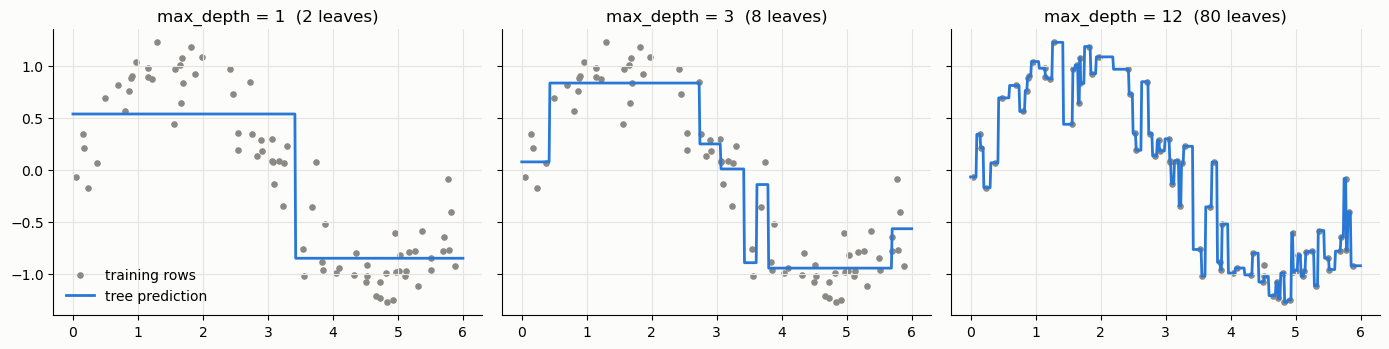

In [15]:
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 6, 80)).reshape(-1, 1)
y_curve = np.sin(x).ravel() + rng.normal(0, 0.25, 80)
grid = np.linspace(0, 6, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, depth in zip(axes, [1, 3, 12]):
    reg = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(x, y_curve)
    ax.scatter(x, y_curve, s=14, color="#8a8984", label="training rows")
    ax.plot(grid, reg.predict(grid), color=BLUE, lw=2, label="tree prediction")
    ax.set_title(f"max_depth = {depth}  ({reg.get_n_leaves()} leaves)")
axes[0].legend(loc="lower left", frameon=False)
plt.tight_layout(); plt.show()

Depth 1 is one split (two means); depth 3 follows the curve; depth 12 gives almost every row its own leaf and **memorises the noise**: the same overfitting as in classification. The same depth curve on a real dataset (scikit-learn's built-in diabetes data: predict disease progression, a number from about 25 to 346), with **RMSE** (in the target's units, large errors count more):

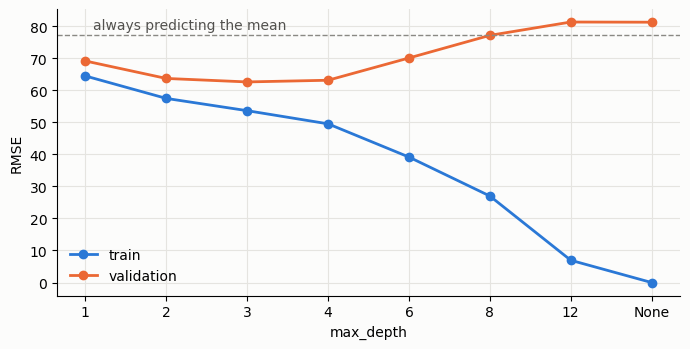

depth 3, out-of-fold:  RMSE 62.6  ·  MAE 50.2  ·  R² 0.34


In [16]:
data = load_diabetes(as_frame=True)
X_reg, y_reg = data.data, data.target
folds = KFold(n_splits=5, shuffle=True, random_state=42)          # no stratification for a number
rows = []
for depth in [1, 2, 3, 4, 6, 8, 12, None]:
    res = cross_validate(DecisionTreeRegressor(max_depth=depth, random_state=42), X_reg, y_reg, cv=folds,
                         scoring="neg_root_mean_squared_error", return_train_score=True)
    rows.append({"max_depth": str(depth), "train RMSE": -res["train_score"].mean(), "validation RMSE": -res["test_score"].mean()})
curve = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve["max_depth"], curve["train RMSE"], "o-", color=BLUE, lw=2, label="train")
ax.plot(curve["max_depth"], curve["validation RMSE"], "o-", color=ORANGE, lw=2, label="validation")
ax.axhline(y_reg.std(), color="#8a8984", ls="--", lw=1); ax.text(0.1, y_reg.std() + 2, "always predicting the mean", color="#52514e")
ax.set_xlabel("max_depth"); ax.set_ylabel("RMSE"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

best = DecisionTreeRegressor(max_depth=3, random_state=42)
pred = cross_val_predict(best, X_reg, y_reg, cv=folds)
print(f"depth 3, out-of-fold:  RMSE {np.sqrt(mean_squared_error(y_reg, pred)):.1f}  ·  MAE {mean_absolute_error(y_reg, pred):.1f}  ·  R² {r2_score(y_reg, pred):.2f}")

- **RMSE** and **MAE** are in the target's units (MAE: the typical error; RMSE punishes large errors more). **R²**: the share of the target's variance explained (0 = no better than predicting the mean, 1 = perfect).
- Validation RMSE is lowest around depth 3 and rises after: the same train/validation gap you know from classification. From depth 8 on, the tree does **worse than always predicting the mean**.
- **You've already used regression trees:** gradient boosting and XGBoost fit each new tree to a *number* (what the previous trees still get wrong), even when the task is classification.

## 8 · What this notebook adds to your pipeline

| File | Change |
|---|---|
| `requirements.txt` | `xgboost>=2.0` (on macOS, XGBoost also needs `brew install libomp`) |
| `src/model.py` | `"xgboost": XGBClassifier` in `_MODELS`; new `VoteSelector` class; `build_pipeline()` takes `selection_config` and `memory` |
| `config.yaml` | `model.type: xgboost` (+ its params); new `feature_selection` section; `xgboost` search space (incl. `gamma`, `reg_alpha`) |
| `main.py` | passes `feature_selection` and a cache folder to `build_pipeline()`; tunes `select__min_votes` with the model; prints the kept features; scoreboard column `feature_selection` |
| `src/results.py` | the report header records the feature-selection setting |

## 9 · Takeaways
- **XGBoost** = gradient boosting with brakes inside every split (`gamma`, `reg_alpha`, `reg_lambda`, `min_child_weight`); aggressive defaults, so always tune it. Tuned, it ties with HistGB on COMPAS: compare on your data with nested CV.
- Useless columns make models **worse, slower and harder to explain**; flexible models suffer most.
- **Filter** (fast, one feature at a time), **wrapper** (many fits), **embedded** (the model selects), **combined** (models vote).
- Selection is **learned from the labels**: it goes **inside** the Pipeline, re-fitted in every fold. Selecting first and cross-validating after can make pure noise look like a good model.
- Tuning how much to select is tuning: report **nested CV**.
- A decision tree handles **multiclass** (k class shares per leaf) and **regression** (a mean per leaf) with the same algorithm; only the leaf value, the split criterion and the metrics change.

## Challenges (in your own pipeline)

**Part A is required**: it brings your pipeline up to this week's version, and it's what the weekly check looks for. Copy the code from this notebook: every pipeline function in it is exactly the course pipeline's version.

<div style="background-color:#ede7f6; border-left:6px solid #5e35b1; padding:10px 14px; border-radius:4px"><b>A1 · XGBoost</b> (section 2)<br><ul><li><code>pip install xgboost</code> and add <code>xgboost>=2.0</code> to <code>requirements.txt</code> (macOS: <code>brew install libomp</code> first if the import fails).</li><li><code>src/model.py</code>: import <code>XGBClassifier</code>; add <code>"xgboost"</code> to <code>_MODELS</code>.</li><li><code>config.yaml</code>: <code>model.type: "xgboost"</code> with its <code>params</code>; add the <code>xgboost</code> search space.</li><li><b>Check:</b> <code>python main.py</code> with <code>tuning.enabled: false</code> runs XGBoost.</li></ul></div>

<div style="background-color:#ede7f6; border-left:6px solid #5e35b1; padding:10px 14px; border-radius:4px"><b>A2 · Feature selection</b> (sections 4 and 6)<br><ul><li><code>src/model.py</code>: add <code>VoteSelector</code> (needs <code>import numpy as np</code>, <code>BaseEstimator</code>, <code>SelectorMixin</code>); replace <code>build_pipeline()</code>.</li><li><code>config.yaml</code>: add the <code>feature_selection</code> section.</li><li><code>main.py</code>: build the pipeline with <code>config["feature_selection"]</code> and a cache folder; with tuning on, merge <code>feature_selection.search_space</code> into the model's search space; print the features kept by the final model.</li><li><b>Check:</b> the output ends with "Features kept: ...", and the results file header shows the selection setting.</li></ul></div>

<div style="background-color:#ede7f6; border-left:6px solid #5e35b1; padding:10px 14px; border-radius:4px"><b>A3 · Does selection pay off?</b><br><ul><li>Run XGBoost <b>tuned</b> twice: <code>feature_selection.enabled: true</code> and <code>false</code>. Both land on the scoreboard.</li><li>Compare the two runs with <code>corrected_paired_test()</code> (README, "Model evaluation").</li></ul></div>

### README task (due Saturday 23:59)
- Add the W8 row to "Pipeline progress".
- **Feature selection:** the two XGBoost runs (with / without selection), the corrected test, and the features kept. 3–5 sentences: is the smaller model as good? Would you keep selection on, and why?

### Part B · Extra challenges

<div style="background-color:#fce4ec; border-left:6px solid #ad1457; padding:10px 14px; border-radius:4px"><b>B1 · Other selectors.</b> Make the selector a config option (<code>feature_selection.method: vote | kbest | from_model</code>) and compare them on the same folds with the corrected test. Which is fastest for the same score?</div>

<div style="background-color:#fce4ec; border-left:6px solid #ad1457; padding:10px 14px; border-radius:4px"><b>B2 · How many votes?</b> With tuning on, which <code>min_votes</code> does nested CV choose in each outer fold (results file)? Is it the same in every fold? What does that tell you?</div>

## Week 8 summary: everything added to the pipeline this week

| File | Change |
|---|---|
| `requirements.txt` | `xgboost` |
| `src/model.py` | `xgboost` model; `VoteSelector`; `build_pipeline(preprocessing, model, selection, memory)` |
| `config.yaml` | `model.type: xgboost`; `feature_selection` section; `xgboost` search space |
| `main.py` | selection + cache in the pipeline; `select__min_votes` tuned with the model; kept features printed; scoreboard column |
| `src/results.py` | selection setting in the report header |

**By Saturday 23:59** your fork should have: Part A done and the README task written.

<div style="background-color:#fff8e1; border-left:6px solid #f9a825; padding:10px 14px; border-radius:4px">📝 <b>Feedback on the course</b>: anonymous, about 3 minutes: <a href="https://forms.gle/ztjiyG9f5F6iDCqH8">https://forms.gle/ztjiyG9f5F6iDCqH8</a></div>